# Supplemental Figure 7, panel B

i) Barplot showing top BAF-independence features at enhancers (most positive Ridge coefs)

ii) Violin plot comparing accessibility log2FC between enhancers overlapping dREGs (putative active) and non-overlapping enhancers (putative primed)

*Outputs: PanelB.pdf*

# Setup

In [13]:
library(tidyverse)
library(here)
library(patchwork)
library(rtracklayer)
library(ggpointdensity)
here::i_am("figures/SuppFig7/PanelB/PanelB.ipynb")
sessionInfo()

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] ggpointdensity_0.2.1 rtracklayer_1.58.0   GenomicRanges_1.50.2
 [4] GenomeInfoDb_1.34.9  IRanges_2.32.0       S4Vectors_0.36.2    
 [7] BiocGenerics_0.44.0  patchwork_1.3.0      here_1.0.2          
[10] lubridate_1.9.4      forcats_1.0.0        stringr_1.5.1       
[13] dpl

# load data

In [8]:
#ML outputs - feature, Ridge coef, MDI feature importance
ml_0.5h <- read.delim(
    here("inputs","ReModEx","GM12878","enh_only","time_0.5h_w_dREG", "feature_importance.csv"),
    sep=',')

atac_fc <- read.delim(
    here("inputs", "DARs", "time_0.5h_DARs.tsv"), sep='\t') %>% arrange(seqnames,start)

dREG_veh <- import("/mnt/disk/home/agulka/projects/PROseq_IFN/PROseq_GM12878_IFN/dreg/veh/veh.dREG.peak.full.bed.gz", format="BED", extraCols = c(dreg_score = "numeric", pvalue = "numeric", summit = "numeric"))

# plot top BAF-independence features from ML

In [5]:
p1 <- ml_0.5h %>% arrange(desc(Ridge_coef)) %>% head(10) %>%
    ggplot(aes(x=Ridge_coef, fill=feature=="veh", y=reorder(feature, Ridge_coef))) +
    geom_col(color="black", aes(linewidth=feature=="veh")) +
    theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15), legend.position="bottom") +
    scale_fill_manual(values=c("grey", "firebrick"))+
    scale_x_continuous(limits=c(0,0.12), breaks=seq(0,0.12,by=0.06)) +
    scale_linewidth_manual(values=c(0.5,1)) + 
    ggtitle("Top 10 BAFindep features")

# plot violin

dREG,n()
<lgl>,<int>
FALSE,23160
TRUE,11885


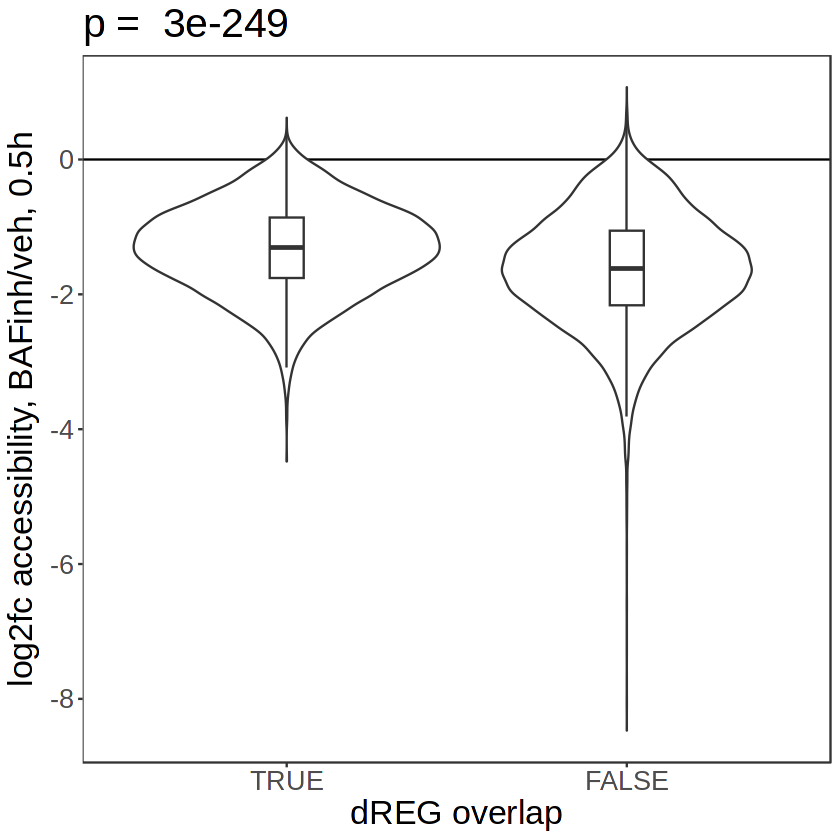

In [9]:
#annotate cREs by dREG overlap
dar_0.5 <- atac_fc %>% 
    mutate(dREG=overlapsAny(makeGRangesFromDataFrame(atac_fc), dREG_veh))

#add dREG score as metadata field
ol <- findOverlaps(makeGRangesFromDataFrame(atac_fc), dREG_veh)
dar_0.5$score <- NA
dar_0.5$score[queryHits(ol)] <- as.numeric(dREG_veh$dreg_score[subjectHits(ol)])

#filter to include enhancers (H3K4me1+, TSS-)
dar_0.5_enh <- dar_0.5 %>% filter(grepl("enh", type))

#generate plot
p2 <- dar_0.5_enh %>% 
    ggplot(aes(x=factor(dREG, levels=c("TRUE", "FALSE")), y=logFC)) + 
    geom_hline(yintercept=0) + 
    geom_violin() + geom_boxplot(width=.1, outlier.shape=NA) +
    theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=20)) +
    xlab("dREG overlap") + ylab("log2fc accessibility, BAFinh/veh, 0.5h") +
    ggtitle(paste("p = ", 
                  format(wilcox.test(formula=logFC~factor(dar_0.5_enh$dREG), #test whether accessibility change differs between dREG+ and dREG- enhancers
                                     data=dar_0.5_enh, alternative="less")$p.value, digits=2)))
p2
#summarize numbers of enhancers in each group
dar_0.5_enh %>% group_by(dREG) %>% summarize(n())

# compile plots

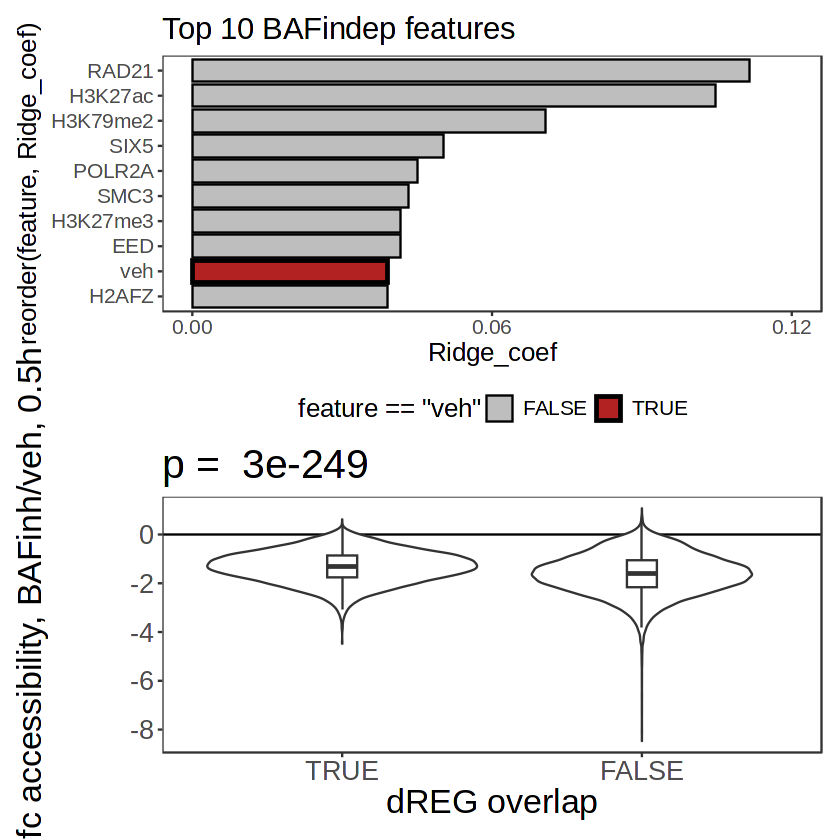

In [10]:
p1 / p2
ggsave("PanelB.pdf", width=4, height=8)